# 28 · Speed: Python loops vs `mujoco.rollout` multithreading, and a first look at MJX

In [1]:
import time, os, mujoco, mujoco_menagerie as mm, numpy as np, matplotlib.pyplot as plt
from mujoco import rollout

def panda():
    m = mm.load("franka_emika_panda"); d = mujoco.MjData(m)
    mujoco.mj_resetDataKeyframe(m, d, 0)
    return m, d

def initial_states(m, d, n, rng):
    spec = mujoco.mjtState.mjSTATE_FULLPHYSICS
    size = mujoco.mj_stateSize(m, spec)
    out = np.zeros((n, size))
    for i in range(n):
        mujoco.mj_resetDataKeyframe(m, d, 0)
        d.qpos[:7] += rng.normal(0, 0.2, 7)
        mujoco.mj_getState(m, d, out[i], spec)
    return out

def python_loop(m, d, x0, ctrl):
    spec = mujoco.mjtState.mjSTATE_FULLPHYSICS
    for i in range(len(x0)):
        mujoco.mj_setState(m, d, x0[i], spec)
        for t in range(ctrl.shape[1]):
            d.ctrl[:] = ctrl[i, t]
            mujoco.mj_step(m, d)

In [2]:
m, d = panda()
rng = np.random.default_rng(0)
nbatch, nstep = 64, 500
x0 = initial_states(m, d, nbatch, rng)
ctrl = np.repeat(d.ctrl[None, None, :], nbatch, 0).repeat(nstep, 1) + rng.normal(0, 0.05, (nbatch, nstep, m.nu))

t0 = time.perf_counter(); python_loop(m, d, x0, ctrl); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); state, sens = rollout.rollout(m, d, x0, ctrl); t_r1 = time.perf_counter() - t0
nthread = os.cpu_count()
datas = [mujoco.MjData(m) for _ in range(nthread)]
t0 = time.perf_counter(); state, sens = rollout.rollout(m, datas, x0, ctrl); t_rn = time.perf_counter() - t0
total = nbatch * nstep
for name, t in [("python loop", t_py), ("rollout, 1 thread", t_r1), (f"rollout, {nthread} threads", t_rn)]:
    print(f"{name:22s} {t:6.2f} s   {total / t:12,.0f} steps/s")
print("state array:", state.shape, "(nbatch, nstep, state size)")

python loop              0.36 s         89,531 steps/s
rollout, 1 thread        0.29 s        108,964 steps/s
rollout, 16 threads      0.05 s        659,356 steps/s
state array: (64, 500, 19) (nbatch, nstep, state size)


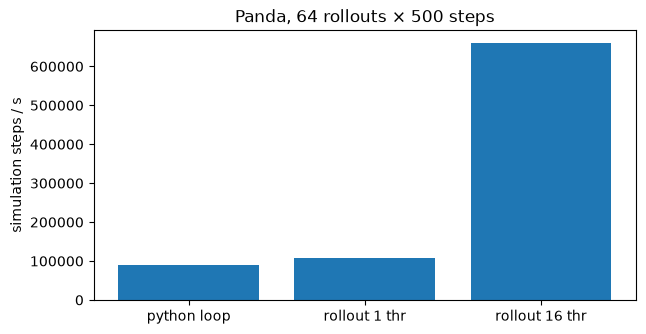

In [3]:
plt.figure(figsize=(7, 3.5))
plt.bar(["python loop", "rollout 1 thr", f"rollout {nthread} thr"], [total / t_py, total / t_r1, total / t_rn])
plt.ylabel("simulation steps / s"); plt.title("Panda, 64 rollouts × 500 steps"); plt.show()

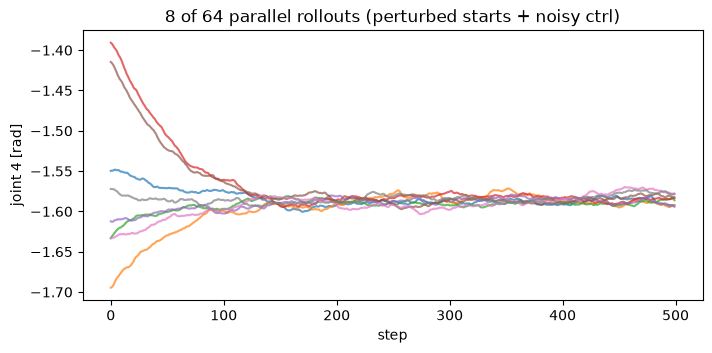

In [4]:
qpos_traj = state[:, :, 1:1 + m.nq]
plt.figure(figsize=(8, 3.5))
for i in range(8):
    plt.plot(qpos_traj[i, :, 3], alpha=0.7)
plt.xlabel("step"); plt.ylabel("joint 4 [rad]"); plt.title("8 of 64 parallel rollouts (perturbed starts + noisy ctrl)"); plt.show()

In [5]:
try:
    import jax
    from mujoco import mjx
    mx = mjx.put_model(m)
    batch = jax.vmap(lambda key: mjx.make_data(mx).replace(qpos=mjx.make_data(mx).qpos + 0.1 * jax.random.normal(key, (m.nq,))))(jax.random.split(jax.random.PRNGKey(0), 1024))
    step = jax.jit(jax.vmap(mjx.step, in_axes=(None, 0)))
    batch = step(mx, batch)
    print("MJX: stepped 1024 Pandas in parallel on", jax.devices()[0])
except ImportError:
    print("MJX not installed here. On a Colab GPU:  pip install mujoco-mjx 'jax[cuda12]'  (used in S05 for Go2 locomotion)")

MJX not installed here. On a Colab GPU:  pip install mujoco-mjx 'jax[cuda12]'  (used in S05 for Go2 locomotion)
